In [46]:
!pip install rdkit

In [47]:
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors
from sklearn.model_selection import train_test_split, cross_val_score , GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

###**Data loading**

In [48]:
url = "https://raw.githubusercontent.com/dataprofessor/data/master/delaney.csv"
esol_data = pd.read_csv(url)

### **Data Testing**


In [49]:
esol_raw = esol_data.copy()

print(esol_raw.isna().sum())
print(esol_raw.shape)
print(esol_raw.duplicated().sum())
print(esol_raw.info())
print(esol_raw.head(1))

Compound ID                             0
measured log(solubility:mol/L)          0
ESOL predicted log(solubility:mol/L)    0
SMILES                                  0
dtype: int64
(1144, 4)
0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1144 entries, 0 to 1143
Data columns (total 4 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Compound ID                           1144 non-null   object 
 1   measured log(solubility:mol/L)        1144 non-null   float64
 2   ESOL predicted log(solubility:mol/L)  1144 non-null   float64
 3   SMILES                                1144 non-null   object 
dtypes: float64(2), object(2)
memory usage: 35.9+ KB
None
                 Compound ID  measured log(solubility:mol/L)  \
0  1,1,1,2-Tetrachloroethane                           -2.18   

   ESOL predicted log(solubility:mol/L)          SMILES  
0                                -2.794  ClCC(Cl)(Cl)C

In [50]:
empty_mask = esol_raw["SMILES"].str.strip() == ""

print("Empty smiles :", empty_mask.sum())

bad_idx = []
for idx, smi in esol_raw["SMILES"].items():
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        bad_idx.append(idx)

print("Bad smiles :", len(bad_idx))

Empty smiles : 0
Bad smiles : 0


### **Data Cleaning**

In [51]:
dupl_esol = esol_raw["SMILES"].duplicated().sum()
salt_esol = esol_raw["SMILES"].str.contains(r"\.", regex=True).sum()

print("Duplicated smiles :", dupl_esol)
print("Solt smiles :", salt_esol)

dup_all = esol_raw["SMILES"].duplicated(keep=False)

dup_check = esol_raw[dup_all].sort_values("SMILES")[["Compound ID", "SMILES", "measured log(solubility:mol/L)"]]
print(dup_check.to_string())


clean_esol = esol_raw[~dup_all].copy()


print("All duplicated : ", dup_all.sum())
print("clean Esol Data : ", len(clean_esol))


Duplicated smiles : 16
Solt smiles : 0
                Compound ID                                          SMILES  measured log(solubility:mol/L)
1046                  RTI 7                 C2c1ccccc1N(CCF)C(=O)c3ccccc23                           -3.535
1039                 RTI 20                 C2c1ccccc1N(CCF)C(=O)c3ccccc23                           -4.799
288     3-Methyl-2-pentanol                                       CCC(C)CCO                          -0.720
289     3-Methyl-2-pentanol                                       CCC(C)CCO                          -0.710
870               Nitramine    CCN(CC)c1c(cc(c(N)c1N(=O)=O)C(F)(F)F)N(=O)=O                          -3.561
607             Dinitramine    CCN(CC)c1c(cc(c(N)c1N(=O)=O)C(F)(F)F)N(=O)=O                          -5.470
668   Ethyl-p-aminobenzoate                             CCOC(=O)c1ccc(N)cc1                          -2.100
428              Benzocaine                             CCOC(=O)c1ccc(N)cc1                      

### **Descriptors**

In [52]:
descriptor_funcs = Descriptors.descList


def cal_all_descriptor(smiles):
    mol = Chem.MolFromSmiles(smiles)
    result = {}
    for name, func in descriptor_funcs:
        try:
            result[name] = func(mol)
        except Exception:
            result[name] = np.nan
    return result

rows = [cal_all_descriptor(smi) for smi in clean_esol["SMILES"]]

all_desc_df = pd.DataFrame(rows, index= clean_esol.index)

print("Shape:", all_desc_df.shape)
print("NaN row:", all_desc_df.isna().any(axis=1).sum())

x = all_desc_df
y = clean_esol["measured log(solubility:mol/L)"]

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Test RMSE:", np.sqrt(mse))
print("Test R2:", r2)

Shape: (1112, 217)
NaN row: 0
X_train: (889, 217)
X_test: (223, 217)
Test RMSE: 0.6515010329622636
Test R2: 0.8857322353460266


In [53]:
scores = cross_val_score(model, x, y, cv=5, scoring="r2")
print(scores)
print("Mean CV R²:", scores.mean())
print("Std:", scores.std())

[0.89878856 0.89653906 0.86360538 0.88018135 0.82530215]
Mean CV R²: 0.8728832992242814
Std: 0.02695917251509132


### **Feature selection**

In [54]:
importance = pd.Series(model.feature_importances_, index=x.columns).sort_values(ascending=False)
print(importance.head(20))

MolLogP                0.733274
MolMR                  0.032613
Chi1v                  0.023871
Chi3v                  0.016072
BertzCT                0.014199
FpDensityMorgan1       0.007219
MaxPartialCharge       0.006369
MinPartialCharge       0.005700
SMR_VSA10              0.005072
MaxAbsPartialCharge    0.004903
NumHAcceptors          0.004364
qed                    0.004209
Chi4v                  0.003945
VSA_EState8            0.003937
PEOE_VSA6              0.003868
MaxAbsEStateIndex      0.003456
Ipc                    0.003309
TPSA                   0.003298
BCUT2D_MWLOW           0.003209
MinAbsEStateIndex      0.003079
dtype: float64


In [55]:
top10_features = importance.head(10).index.tolist()

scores_sel = cross_val_score(
    RandomForestRegressor(n_estimators=100, random_state=42),
    x[top10_features], y, cv=5, scoring="r2"
)

print("Top 10 features Mean CV R²:", scores_sel.mean(), "Top 10 features Std:", scores_sel.std())

Top 10 features Mean CV R²: 0.8709824883969979 Top 10 features Std: 0.031623026512363824


In [56]:
group_features = [
    "MolLogP", "Chi3v", "BertzCT", "MaxPartialCharge",
    "TPSA", "NumHAcceptors", "qed", "BCUT2D_MWLOW", "FpDensityMorgan1", "MolMR"
]

scores_group = cross_val_score(
    RandomForestRegressor(n_estimators=100, random_state=42),
    x[group_features], y, cv=5, scoring="r2"
)
print("Group features Mean CV R²:", scores_group.mean(), "Std:", scores_group.std())

Group features Mean CV R²: 0.8739939760249186 Std: 0.03517806970763083


### **Tuning (dev set)**

In [57]:
param_grid = {
    "max_depth": [None, 5, 10],
    "min_samples_leaf": [1, 3, 5],
    "max_features": [0.5, 1.0],
}

x_sel = x[group_features]
x_dev, x_hold, y_dev, y_hold = train_test_split(
    x_sel, y, test_size=0.2, random_state=42
)

grid = GridSearchCV(
    RandomForestRegressor(n_estimators=100, random_state=42),
    param_grid, cv=5, scoring="r2"
)
grid.fit(x_dev, y_dev)

print("Best params:", grid.best_params_)
print("Dev CV R²:", grid.best_score_)

Best params: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1}
Dev CV R²: 0.8924118680997243


## Evaluation (hold-out set)

In [58]:
best = grid.best_estimator_
y_hold_pred = best.predict(x_hold)

print("Hold-out RMSE:", np.sqrt(mean_squared_error(y_hold, y_hold_pred)))
print("Hold-out R²:", r2_score(y_hold, y_hold_pred))

Hold-out RMSE: 0.6688859770822821
Hold-out R²: 0.8795525258943544


### **Plot**

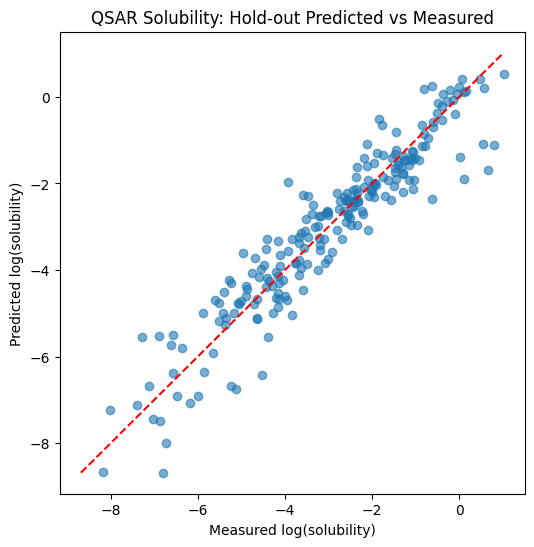

In [59]:
plt.figure(figsize=(6, 6))
plt.scatter(y_hold, y_hold_pred, alpha=0.6)
lims = [min(y_hold.min(), y_hold_pred.min()), max(y_hold.max(), y_hold_pred.max())]
plt.plot(lims, lims, "r--")
plt.xlabel("Measured log(solubility)")
plt.ylabel("Predicted log(solubility)")
plt.title("QSAR Solubility: Hold-out Predicted vs Measured")
plt.show()

In [60]:
big_err = pd.DataFrame({"measured": y_hold, "predicted": y_hold_pred})
big_err["error"] = big_err["predicted"] - big_err["measured"]
print(big_err.reindex(big_err["error"].abs().sort_values(ascending=False).index).head(5))

      measured  predicted    error
406      0.651   -1.67760 -2.32860
905      0.106   -1.89746 -2.00346
1137    -3.930   -1.96701  1.96299
1065     0.790   -1.11645 -1.90645
1061    -4.522   -6.41357 -1.89157


In [61]:
print("Full RMSE:", np.sqrt(mean_squared_error(big_err["measured"], big_err["predicted"])))
print("Excluding top-5 RMSE:", np.sqrt(mean_squared_error(rest["measured"], rest["predicted"])))

Full RMSE: 0.6688859770822821
Excluding top-5 RMSE: 0.6030120728709198
